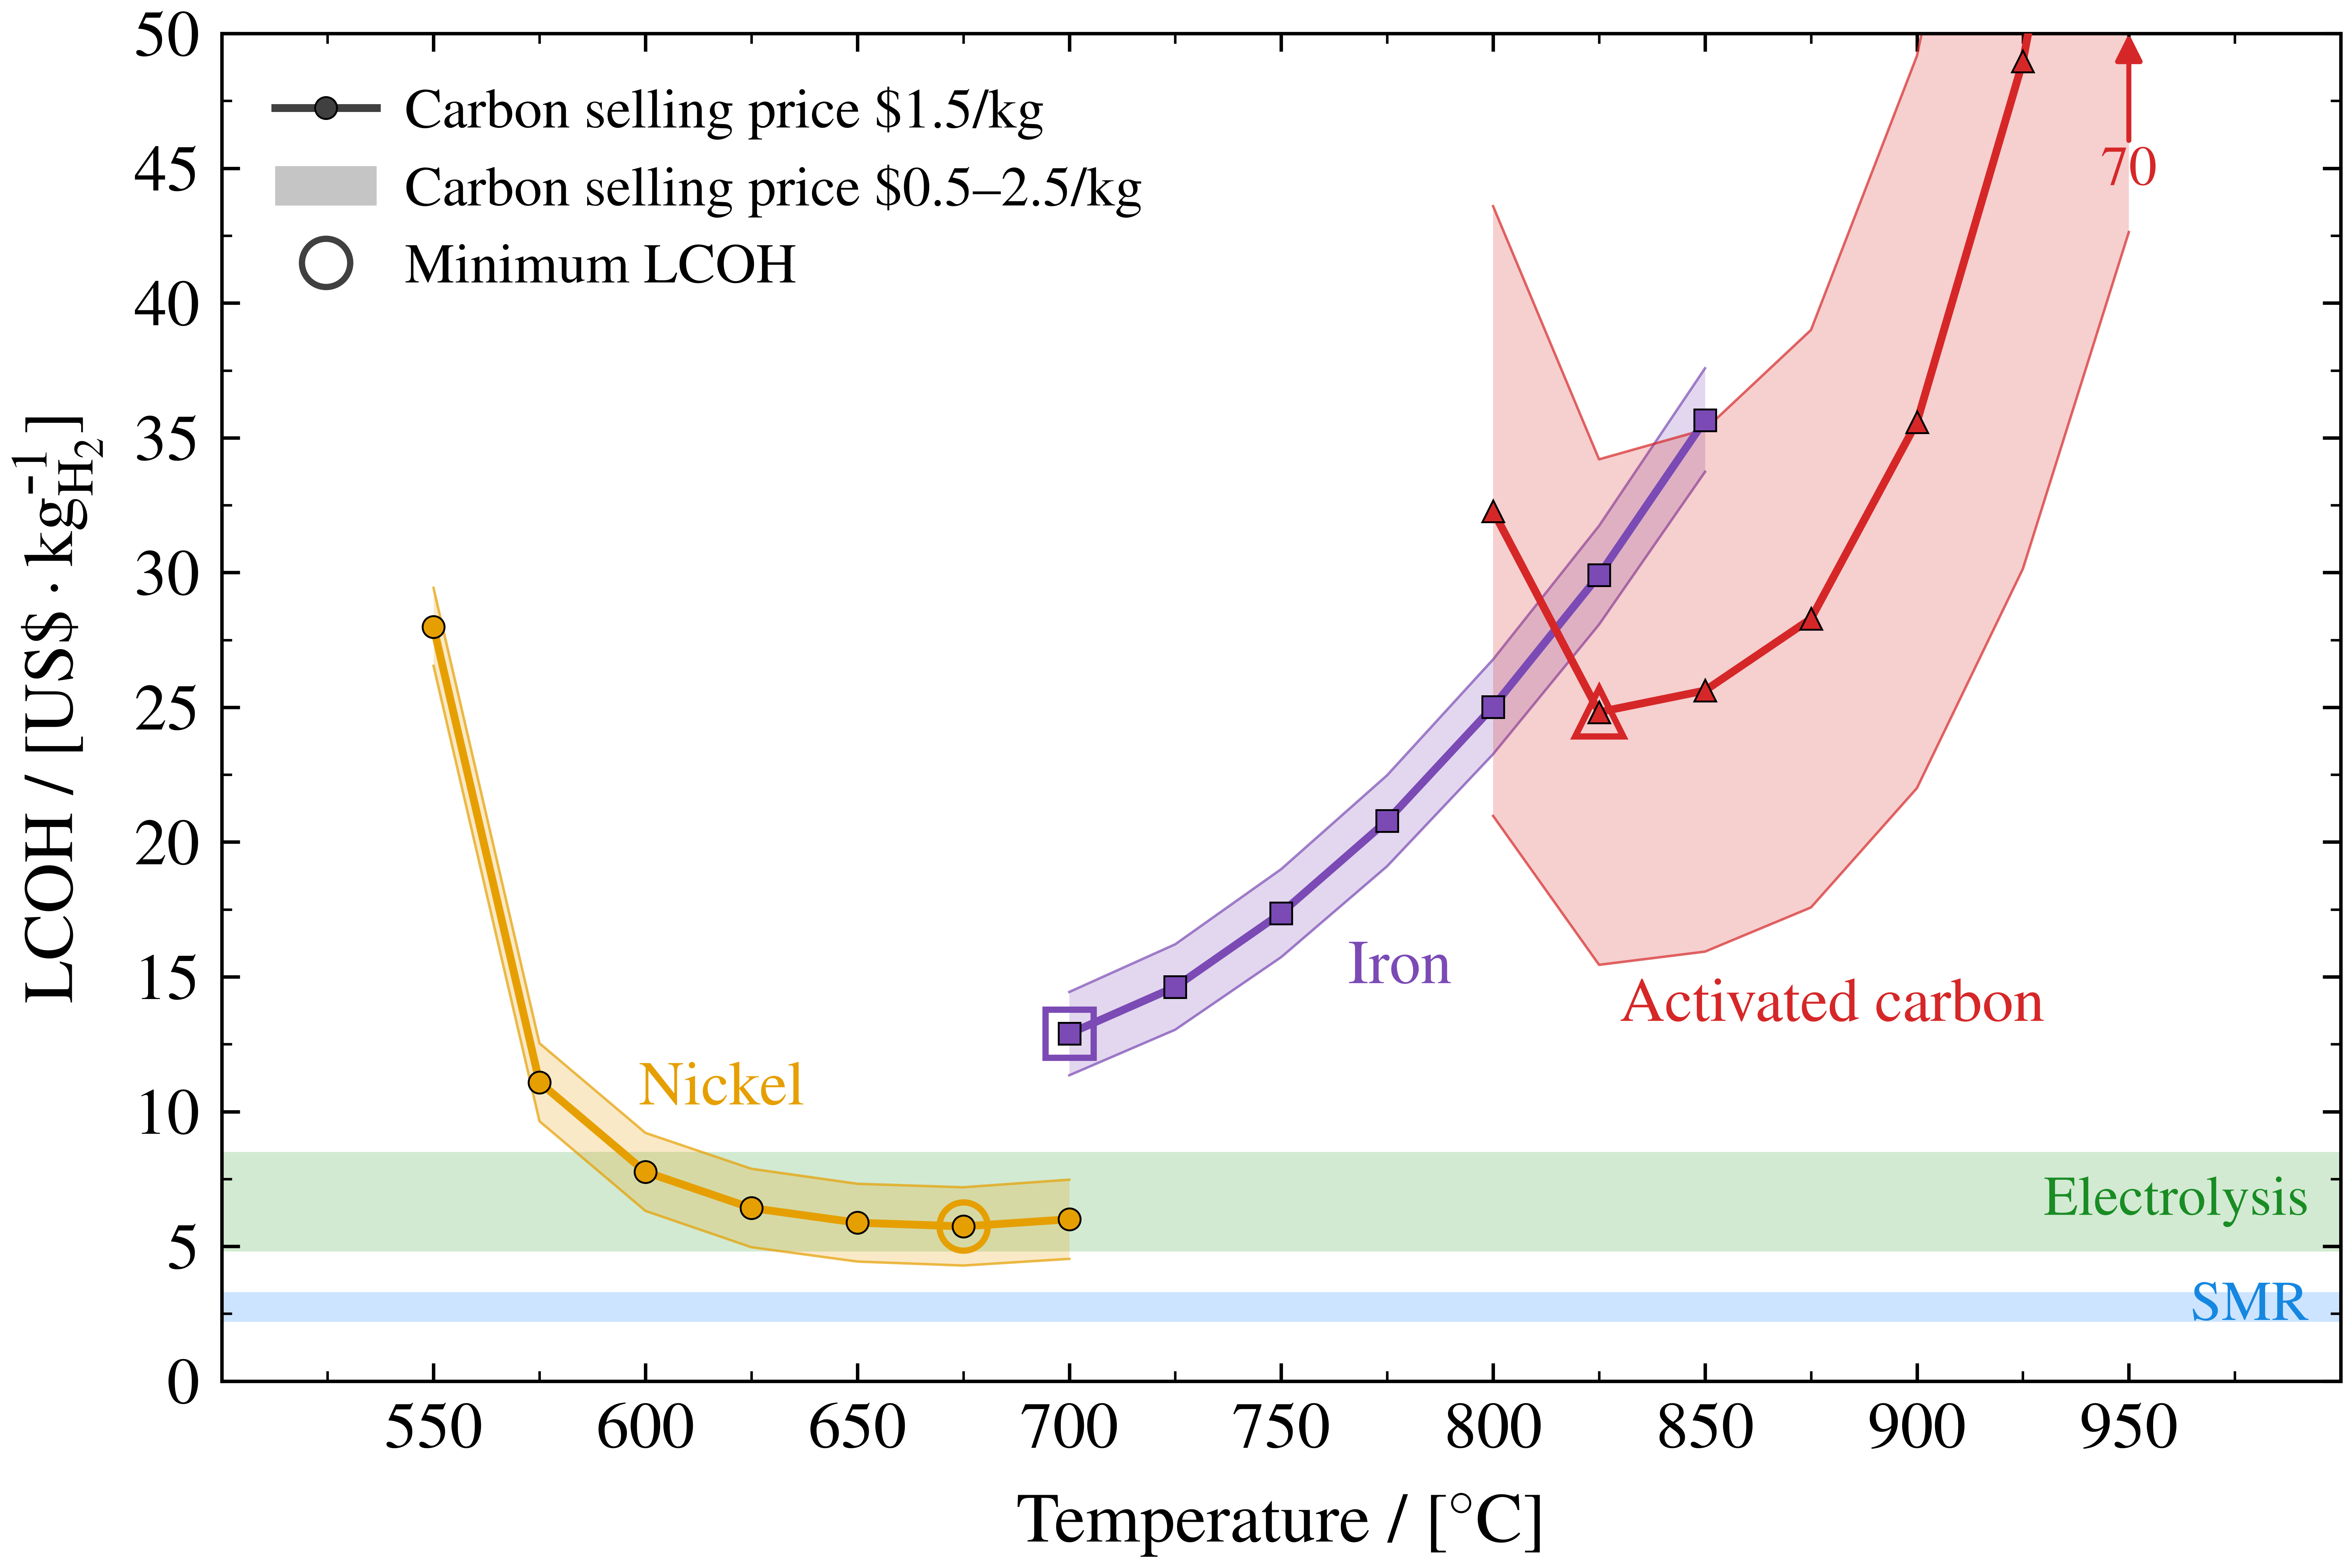

In [1]:
# Average LCOH as a function of temperature for each catalyst, with the
# sensitivity to the solid carbon selling price shown as a shaded band:
# line = 1.5 US$/kg (baseline), band = 0.5 (upper edge) to 2.5 US$/kg (lower edge).

import json
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import scienceplots  # noqa: F401  (registers the "science" styles)
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import FixedLocator, MultipleLocator

# ---------------------------------------------------------------------------
# Plot style
# ---------------------------------------------------------------------------
TICK_FONT = 21.0
AXIS_LABEL_FONT = 22.5
LEGEND_FONT = 18.0
LABEL_FONT = 20.0
REFERENCE_FONT = 18.0

plt.style.use(["science", "ieee"])
mpl.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Times"],
    "font.size": TICK_FONT,
    "axes.labelsize": AXIS_LABEL_FONT,
    "xtick.labelsize": TICK_FONT,
    "ytick.labelsize": TICK_FONT,
    "legend.fontsize": LEGEND_FONT,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "text.color": "black",
    "axes.labelcolor": "black",
    "axes.edgecolor": "black",
    "xtick.color": "black",
    "ytick.color": "black",
    "axes.grid": False,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

# ---------------------------------------------------------------------------
# Configuration
# ---------------------------------------------------------------------------
# Catalysts: colour, marker, and where to put the direct label (data coords)
CATALYSTS = [
    {"folder": "NiMP", "label": "Nickel",           "color": "#E69F00", "marker": "o", "label_xy": (618, 10.8)},
    {"folder": "FeMP", "label": "Iron",             "color": "#7B4AB5", "marker": "s", "label_xy": (778, 15.3)},
    {"folder": "ACMP", "label": "Activated carbon", "color": "#D62728", "marker": "^", "label_xy": (880, 13.9)},
]

# Solid carbon selling prices [US$/kg]; keys of "lcoh_average_by_carbon_price"
# in each LCOH_temperature.json (written by each CH4_CCS notebook)
PRICE_LOW, PRICE_MID, PRICE_HIGH = "0.5", "1.5", "2.5"

# Benchmark LCOH ranges [US$/kg]: (min, max, fill colour, text colour)
REFERENCE_BANDS = {
    "SMR":          (2.2, 3.3, "#bcdcff", "#1687e0"),
    "Electrolysis": (4.8, 8.5, "#c3e3c3", "#198c24"),
}

BAND_ALPHA = 0.22
LINE_WIDTH = 2.5
MARKER_SIZE = 7

X_LIMITS = (500, 1000)
X_MAJOR_TICKS = np.arange(550, 951, 50)
X_MINOR_TICKS = np.arange(525, 976, 50)

Y_LIMITS = (0, 50)   # points above are marked with an arrow and their value
Y_MAJOR_STEP = 5
Y_MINOR_STEP = 2.5

OUTPUT_FILE = "figure-5.pdf"


# ---------------------------------------------------------------------------
# Load data
# ---------------------------------------------------------------------------
def find_project_root(required_folders):
    """Walk up from this file (or the CWD) until a folder containing all
    ``required_folders`` is found."""
    try:
        start_dir = Path(__file__).resolve().parent
    except NameError:  # running inside a notebook
        start_dir = Path.cwd()

    for candidate in [start_dir, *start_dir.parents]:
        if all((candidate / folder).is_dir() for folder in required_folders):
            return candidate
    raise FileNotFoundError("Project root not found.")


def load_lcoh_vs_temperature(results_file):
    """Return the temperatures and {carbon price key: average LCOH} arrays."""
    with open(results_file, "r") as f:
        results = json.load(f)

    if "lcoh_average_by_carbon_price" not in results:
        raise KeyError(
            f"{results_file} has no carbon-price results. Rerun the "
            "'Save LCOH vs Temperature' cell of that catalyst's CH4_CCS notebook."
        )

    temperature = np.asarray(results["temperature"], dtype=float)
    lcoh_by_price = {
        price: np.asarray(lcoh, dtype=float)
        for price, lcoh in results["lcoh_average_by_carbon_price"].items()
    }
    return temperature, lcoh_by_price


project_root = find_project_root([c["folder"] for c in CATALYSTS])

for catalyst in CATALYSTS:
    results_file = project_root / catalyst["folder"] / "Results_TEA" / "LCOH_temperature.json"
    catalyst["temperature"], catalyst["lcoh_by_price"] = load_lcoh_vs_temperature(results_file)


# ---------------------------------------------------------------------------
# Figure
# ---------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10.8, 7.2))

# Benchmark ranges as shaded horizontal bands with a label on the right
for name, (y_low, y_high, fill_color, text_color) in REFERENCE_BANDS.items():
    ax.axhspan(y_low, y_high, facecolor=fill_color, alpha=0.75,
               edgecolor="none", zorder=0)
    ax.text(0.985, (y_low + y_high) / 2, name,
            transform=ax.get_yaxis_transform(),  # x in axes coords, y in data
            color=text_color, fontsize=REFERENCE_FONT, fontweight="bold",
            ha="right", va="center", zorder=1)

y_top = Y_LIMITS[1]
for catalyst in CATALYSTS:
    T = catalyst["temperature"]
    lcoh = catalyst["lcoh_by_price"]
    color = catalyst["color"]

    # Carbon-price band: 0.5 US$/kg (upper edge) to 2.5 US$/kg (lower edge)
    ax.fill_between(T, lcoh[PRICE_HIGH], lcoh[PRICE_LOW],
                    color=color, alpha=BAND_ALPHA, linewidth=0, zorder=2)
    for edge in (PRICE_LOW, PRICE_HIGH):
        ax.plot(T, lcoh[edge], color=color, linestyle="-", linewidth=0.8, alpha=0.7, zorder=2)

    # Central line: 1.5 US$/kg (baseline)
    mid = lcoh[PRICE_MID]
    ax.plot(T, mid, color=color, linestyle="-", marker=catalyst["marker"],
            linewidth=LINE_WIDTH, markersize=MARKER_SIZE,
            markeredgecolor="black", markeredgewidth=0.6, zorder=3)

    # Minimum-LCOH temperature (at 1.5 US$/kg): larger open marker
    i_min = int(np.argmin(mid))
    ax.plot(T[i_min], mid[i_min], marker=catalyst["marker"],
            markersize=MARKER_SIZE * 2.2, markerfacecolor="none",
            markeredgecolor=color, markeredgewidth=2.0, linestyle="none", zorder=4)

    # Points of the central line above the y-axis limit: arrow + value
    for t, value in zip(T, mid):
        if value > y_top:
            ax.annotate(
                rf"{value:.0f}", xy=(t, y_top), xytext=(t, y_top - 4.2),
                ha="center", va="top", color=color, fontsize=LEGEND_FONT,
                arrowprops=dict(arrowstyle="-|>", color=color, lw=1.6,
                                shrinkA=0, shrinkB=0),
                zorder=5,
            )

    # Direct label instead of a legend entry
    ax.text(*catalyst["label_xy"], catalyst["label"], color=color,
            fontsize=LABEL_FONT, fontweight="bold", ha="center", va="center",
            zorder=5)

# Axis labels and limits
ax.set_xlabel(r"Temperature / [$^\circ$C]", fontsize=AXIS_LABEL_FONT, labelpad=10)
ax.set_ylabel(r"LCOH / [US\$\,$\cdot$\,kg$_{\mathrm{H_2}}^{\mbox{-}1}$]",
              fontsize=AXIS_LABEL_FONT, labelpad=10)
ax.set_xlim(*X_LIMITS)
ax.set_ylim(*Y_LIMITS)

# Ticks: inward on all four sides
ax.xaxis.set_major_locator(FixedLocator(X_MAJOR_TICKS))
ax.xaxis.set_minor_locator(FixedLocator(X_MINOR_TICKS))
ax.yaxis.set_major_locator(MultipleLocator(Y_MAJOR_STEP))
ax.yaxis.set_minor_locator(MultipleLocator(Y_MINOR_STEP))

ax.tick_params(axis="both", which="both", direction="in", colors="black",
               top=True, bottom=True, left=True, right=True)
ax.tick_params(axis="both", which="major", length=5.8, width=1.1,
               labelsize=TICK_FONT, pad=7)
ax.tick_params(axis="both", which="minor", length=3.2, width=0.8)

for spine in ax.spines.values():
    spine.set_color("black")
    spine.set_linewidth(1.1)

# Key: what the line, band and open marker mean (catalysts are labelled directly)
key_handles = [
    Line2D([], [], color="0.25", linewidth=LINE_WIDTH, marker="o",
           markersize=MARKER_SIZE, markeredgecolor="black", markeredgewidth=0.6,
           label=r"Carbon selling price \$1.5/kg"),
    Patch(facecolor="0.25", alpha=BAND_ALPHA + 0.08, edgecolor="none",
          label=r"Carbon selling price \$0.5--2.5/kg"),
    Line2D([], [], color="0.25", marker="o", markersize=MARKER_SIZE * 2.2,
           markerfacecolor="none", markeredgewidth=2.0, linestyle="none",
           label="Minimum LCOH"),
]
legend = ax.legend(handles=key_handles, loc="upper left", fontsize=LEGEND_FONT,
                   frameon=False,
                   handlelength=1.8, handletextpad=0.5,
                   borderpad=0.45, labelspacing=0.45)

fig.subplots_adjust(left=0.115, right=0.985, bottom=0.155, top=0.985)
fig.savefig(OUTPUT_FILE, format="pdf")
plt.show()